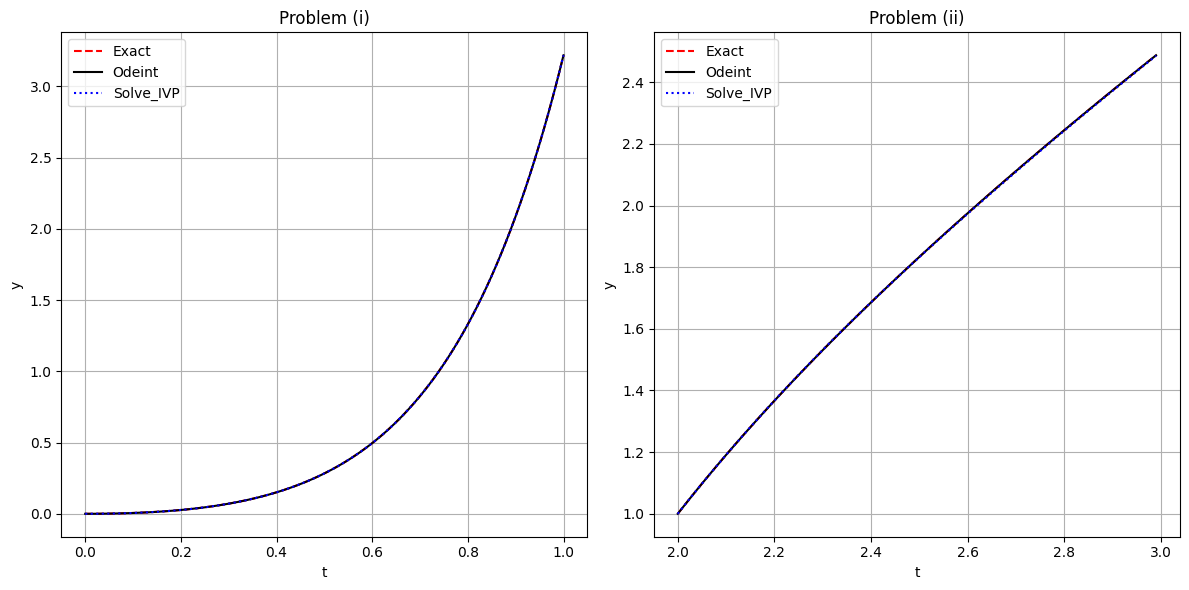


Problem(i)
Solution using odeint:  3.219099341273551
Solution using solve_ivp :  3.2192772041484945
Final error: 
Using odeint : 2.2234059482428847e-08
Using solve_ivp : 0.00017788510900285104

Problem(ii)
Solution using odeint:  2.4874874449083593
Solution using solve_ivp :  2.4858349844039838
Final error:
Using odeint : 7.722429362644334e-09
Using solve_ivp : 0.0016524527819461454



In [1]:
#A3Q1
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.integrate import odeint, solve_ivp 

# ---------------Problem (i)---------------
#Define rhs of ODE 
def f1(y, t):
    return t * np.exp(3 * t) - 2 * y 

def f1_ivp(t, y):
    return t * np.exp(3 * t) - 2 * y 

#Define exact solution 
def exact1(t):
    return (1/5) * t * np.exp(3*t) - (1/25) * np.exp(3*t) + (1/25) * np.exp(-2*t) 

#Time domain 
t1 = np.linspace(0, 1, 100) 
y0_1 = 0

#Solve using odeint
y1_odeint = odeint(f1, y0_1, t1).flatten() 

#solve using solve_ivp 
soll_ivp = solve_ivp(f1_ivp, [0, 1], [y0_1], t_eval=t1) 
y1_ivp = soll_ivp.y[0] 

#Exact 
y1_exact = exact1(t1) 

# --------- Problem ii ----------
def f2(y, t):
    return 1 + (t - y)**2

def f2_ivp(t, y):
    return 1 + (t - y)**2

def exact2(t):
    return t + 1 / (1 - t)

t2 = np.linspace(2, 2.99, 100)  # avoid t = 3 to prevent division by zero
y0_2 = 1

y2_odeint = odeint(f2, y0_2, t2).flatten()
sol2_ivp = solve_ivp(f2_ivp, [2, 2.99], [y0_2], t_eval=t2)
y2_ivp = sol2_ivp.y[0]
y2_exact = exact2(t2) 

#------------plot result-------------
plt.figure(figsize=(12,6)) 

#problem 1 
plt.subplot(1,2, 1)
plt.plot(t1, y1_exact, "r--" ,label = "Exact")
plt.plot(t1, y1_odeint, "k-" ,label = "Odeint") 
plt.plot(t1, y1_ivp, "b:", label = "Solve_IVP") 
plt.title("Problem (i)") 
plt.xlabel("t") 
plt.ylabel("y") 
plt.legend()
plt.grid()

#problem 2 
plt.subplot(1,2, 2)
plt.plot(t2, y2_exact, "r--" ,label = "Exact")
plt.plot(t2, y2_odeint, "k-", label = "Odeint") 
plt.plot(t2, y2_ivp, "b:" ,label = "Solve_IVP") 
plt.title("Problem (ii)") 
plt.xlabel("t") 
plt.ylabel("y") 
plt.legend()
plt.grid() 

plt.tight_layout()
plt.show() 

#-----------error analysis-----------
err1_odeint = np.abs(y1_exact - y1_odeint)
err1_ivp = np.abs(y1_exact - y1_ivp) 
err2_odeint = np.abs(y2_exact - y2_odeint) 
err2_ivp = np.abs(y2_exact - y2_ivp) 

print("\nProblem(i)")
print("Solution using odeint: ", y1_odeint[-1])
print("Solution using solve_ivp : ", y1_ivp[-1]) 
print("Final error: ")
print(f"Using odeint : {err1_odeint[-1]}")
print(f"Using solve_ivp : {err1_ivp[-1]}") 

print("\nProblem(ii)")
print("Solution using odeint: ", y2_odeint[-1])
print("Solution using solve_ivp : ", y2_ivp[-1]) 
print("Final error:")
print(f"Using odeint : {err2_odeint[-1]}")
print(f"Using solve_ivp : {err2_ivp[-1]}\n")


The solution is : x = 9.035750503644232 , y = 7.167738139405786 at t = 100.0



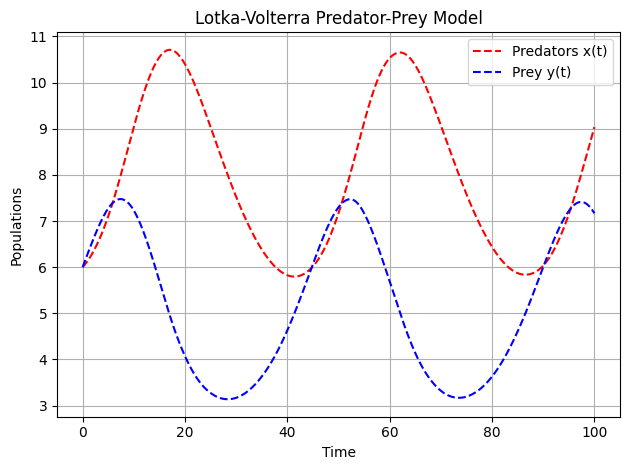

Two populations are first equal at time t =  44.74474474474475 



In [7]:
#A3Q2
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.integrate import solve_ivp

# Define the system of ODEs
def lotka_volterra (t, z) :
    x, y = z
    dx_dt = -0.1*x + 0.02*x*y 
    dy_dt = 0.2*y - 0.025*x*y 
    return dx_dt, dy_dt

#Initial Conditions 
x0 = 6
y0 = 6
t = np.linspace(0, 100, 1000) 

#Solve the system 
solution = solve_ivp(lotka_volterra, [0,100], [x0, y0], t_eval = t)
x = solution.y[0] 
y = solution.y[1]
t = solution.t

print(f"\nThe solution is : x = {x[-1]} , y = {y[-1]} at t = {t[-1]}\n") 

#Plot the results
plt.plot(t, x, "r--", label = "Predators x(t)")
plt.plot(t, y, "b--", label = "Prey y(t)") 
plt.xlabel("Time") 
plt.ylabel("Populations") 
plt.title("Lotka-Volterra Predator-Prey Model")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#Estimate when the two populations are first equal (using tolerance 0.01)
for i in range(1, len(t)) :
    if np.abs(x[i] - y[i]) < 0.01:
        print("Two populations are first equal at time t = ", t[i] , "\n") 
        break 

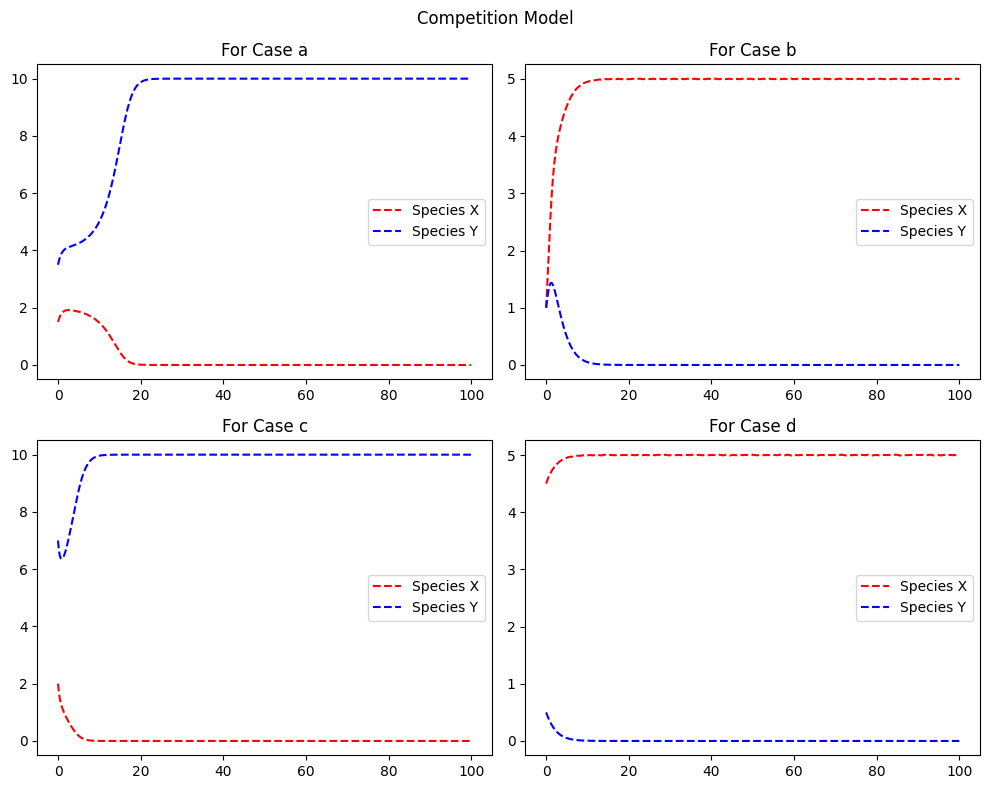

In [12]:
#A3Q3
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp 

#Define the system of ODE
def competition_model(t, z):
    x, y = z 
    dxdt = x * ( 2 - 0.4*x - 0.3*y) 
    dydt = y * ( 1 - 0.1*y - 0.3*x) 
    return dxdt, dydt 

#Time Range and Initial condition
t_eval = np.linspace(0, 100, 1000) 
initial_conditions = {
    'a' : [1.5, 3.5],
    'b' : [1, 1],
    'c' : [2, 7],
    'd' : [4.5, 0.5] 
} 

#Solve and Plot Each Case
plt.figure(figsize = (10, 8)) 

for i , (case, z0) in enumerate(initial_conditions.items(), 1) :
    sol = solve_ivp(competition_model, [0, 100], z0, t_eval=t_eval) 
    x =  sol.y[0] 
    y = sol.y[1]
    t = sol.t 

    plt.subplot(2, 2, i) 
    plt.plot(t, x, "r--", label = "Species X")
    plt.plot(t, y, "b--", label = "Species Y") 
    plt.title(f"For Case {case}") 
    plt.legend()
    plt.grid

plt.suptitle("Competition Model")
plt.tight_layout()
plt.show()

In [16]:
#A3Q4
import numpy as np
import matplotlib.pyplot as plt 
from scipy.integrate import solve_ivp

#constants
g = 32.17 
L = 2 

def pendudlum(t, y):
    theta, omega = y 
    dtheta_dt = omega 
    domega_dt = - (g/L) * np.sin(theta) 
    return [domega_dt, dtheta_dt] 

#Initial Conditions 
theta0 = np.pi/6
omega0 = 0
y0 = [theta0, omega0] 

#Time span 
t_eval = np.arange(0, 2.1, 0.1) 

#Solve ODE 
sol = solve_ivp(pendudlum, [0, 2], y0, t_eval=t_eval) 
theta = sol.y[0]
t = sol.t 

#Print Result 
for i in range(len(sol.t)) :
    t_individual = t[i] 
    theta_individual = theta[i]  
    print(f"\nat t = {t_individual:.2f}, theta = {theta_individual:.8f} radians") 


at t = 0.00, theta = 0.52359878 radians

at t = 0.10, theta = 0.10729869 radians

at t = 0.20, theta = 0.02150800 radians

at t = 0.30, theta = 0.00431129 radians

at t = 0.40, theta = 0.00086526 radians

at t = 0.50, theta = 0.00017317 radians

at t = 0.60, theta = 0.00003498 radians

at t = 0.70, theta = 0.00000714 radians

at t = 0.80, theta = 0.00000159 radians

at t = 0.90, theta = 0.00000027 radians

at t = 1.00, theta = -0.00000001 radians

at t = 1.10, theta = 0.00000011 radians

at t = 1.20, theta = -0.00000040 radians

at t = 1.30, theta = -0.00000042 radians

at t = 1.40, theta = 0.00000105 radians

at t = 1.50, theta = -0.00000036 radians

at t = 1.60, theta = 0.00000070 radians

at t = 1.70, theta = -0.00000024 radians

at t = 1.80, theta = 0.00000045 radians

at t = 1.90, theta = -0.00000028 radians

at t = 2.00, theta = 0.00000048 radians


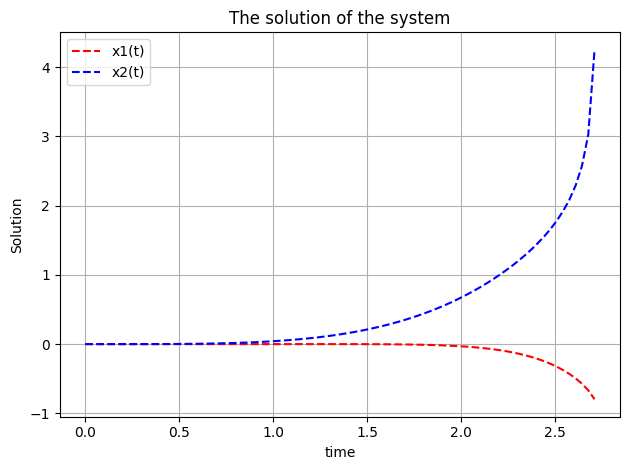

In [19]:
#A3Q5
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.integrate import solve_ivp 

#Define the system 
def system(t, y) :
    y1, y2, y3, y4, y5, y6 = y 
    dy1_dt = y2
    dy2_dt = y3 
    dy3_dt = -2 * y5**2 + y4
    dy4_dt = y5 
    dy5_dt = y6 
    dy6_dt = -y3**3 + y5 + y1 + np.sin(t) 
    return [dy1_dt, dy2_dt, dy3_dt, dy4_dt, dy5_dt, dy6_dt] 

#Initial conditions 
t_sn = np.linspace(0, 10, 300) 
y0 = [0, 0, 0, 0, 0, 0]  

sol = solve_ivp(system, [0, 10], y0, t_eval = t_sn)

x1 = sol.y[0] 
x2 = sol.y[3] 
t = sol.t

#Plot the result
plt.plot(t, x1, "r--", label = "x1(t)")
plt.plot(t, x2, "b--", label = "x2(t)") 
plt.title("The solution of the system")
plt.xlabel("time") 
plt.ylabel("Solution") 
plt.legend()
plt.grid()
plt.tight_layout() 
plt.show() 

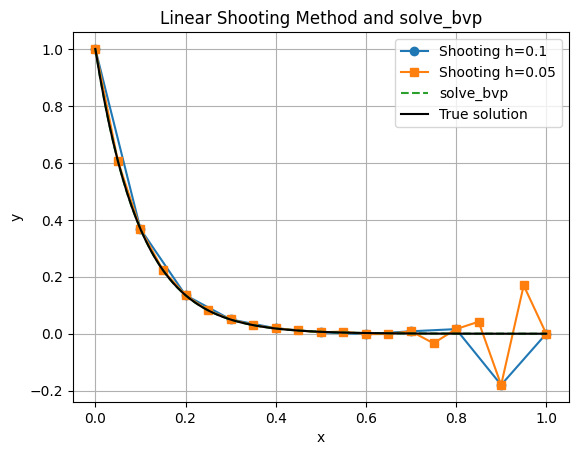

In [21]:
#A3Q6
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp

# Define the system: convert y'' = 100y into first-order system
def system(t, Y):
    return [Y[1], 100*Y[0]]

# Solve two IVPs for the shooting method
def linear_shooting(h):
    x_vals = np.arange(0, 1 + h, h)

    # First IVP: y1(0) = 1, y1'(0) = 0
    sol1 = solve_ivp(system, [0, 1], [1, 0], t_eval=x_vals)
    
    # Second IVP: y2(0) = 0, y2'(0) = 1
    sol2 = solve_ivp(system, [0, 1], [0, 1], t_eval=x_vals)

    y1, y2 = sol1.y[0], sol2.y[0]
    c = (np.exp(-10) - y1[-1]) / y2[-1]
    y = y1 + c * y2 

    return x_vals, y

# Solve with solve_bvp
def solve_with_bvp():
    def ode(x, y):
        return np.vstack((y[1], 100*y[0]))

    def bc(ya, yb):
        return [ya[0] - 1, yb[0] - np.exp(-10)]

    x = np.linspace(0, 1, 100)
    y_guess = np.zeros((2, x.size))
    sol = solve_bvp(ode, bc, x, y_guess)

    return sol.x, sol.y[0]

# Plotting
x1, y1 = linear_shooting(h=0.1)
x2, y2 = linear_shooting(h=0.05)
xbvp, ybvp = solve_with_bvp()
x_true = np.linspace(0, 1, 100)
y_true = np.exp(-10 * x_true)

plt.plot(x1, y1, 'o-', label='Shooting h=0.1')
plt.plot(x2, y2, 's-', label='Shooting h=0.05')
plt.plot(xbvp, ybvp, '--', label='solve_bvp')
plt.plot(x_true, y_true, 'k-', label='True solution')
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Shooting Method and solve_bvp")
plt.grid(True)
plt.show()
